# Rayleigh statistics on independent spatial grids

This example uses a uniform scalar reference fiber, no point reflectors and
zero background loss. The guided backscatter is deliberately weak:
$\rho L=10^{-4}$. We use four left-edge grids and independent reproducible
ensembles. Changing the grid does not preserve one frozen complex fiber.

The comparison with analytic Gaussian statistics is exact for the undepleted
single-scattering field. The all-orders solver and direct-consistent model
are evaluated on the same stored sample. Their agreement with that Gaussian
limit is checked only in this weak regime.

Run all cells in order with PyRayleigh, NumPy, Matplotlib and Jupyter installed,
or from this source checkout. All optical frequencies are absolute Hz; cell
lengths are m. No OFDR processing or strain estimator is used here.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if repo.name == 'examples':
    repo = repo.parent
if (repo/'src'/'pyrayleigh').is_dir():
    sys.path.insert(0, str(repo/'src'))

import pyrayleigh
from pyrayleigh import (Fiber, GuideOptics, Probe, Section, compute_response,
                       compute_response_diagnostics, rayleigh_resolution_report)
from pyrayleigh.constants import SPEED_OF_LIGHT as c

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
nu0, n, L = c/1550e-9, 1.47, 1/16
rho = 1e-4/L
power_scale = rho*L
frequency = nu0+np.linspace(-5e9, 5e9, 65)
probe = Probe(frequency)
guide = GuideOptics(nu0, n, n, gvd=0.)
fiber = Fiber('statistics', L, 293.15, nu0-1e11, nu0+1e11,
              (Section(0., L, guide, 0., rho),))
cell_counts = (8, 16, 32, 64)
ensemble_size = 512
seed_base = 120000
field_atol, field_rtol, energy_atol = 3e-12, 3e-10, 5e-12
print('PyRayleigh', pyrayleigh.__version__, '| NumPy', np.__version__, '| NumPy float64 / complex128')
print(f'L={L:g} m, rho={rho:g} 1/m, rho*L={power_scale:g}, alpha_background=0, reference state')
print(f'nu0={nu0:.12g} Hz; band=10 GHz, {frequency.size} samples, step={frequency[1]-frequency[0]:g} Hz')
print('Cells:', cell_counts, '| independent realizations per grid:', ensemble_size)
print('Seed per realization: seed_base + 10000*grid_index + realization_index; seed_base=', seed_base)
print('Complex field tolerances:', field_atol, field_rtol, '| lossless energy tolerance:', energy_atol)

PyRayleigh 0.1.0.dev0 | NumPy 2.5.4 | NumPy float64 / complex128
L=0.0625 m, rho=0.0016 1/m, rho*L=0.0001, alpha_background=0, reference state
nu0=1.93414489032e+14 Hz; band=10 GHz, 65 samples, step=1.5625e+08 Hz
Cells: (8, 16, 32, 64) | independent realizations per grid: 512
Seed per realization: seed_base + 10000*grid_index + realization_index; seed_base= 120000
Complex field tolerances: 3e-12 3e-10 | lossless energy tolerance: 5e-12


## Independent reference formulas

For a cell of width $h$, $r_j=\sqrt{\rho h/2}(X_j+iY_j)$, with independent
standard normals. Thus $E[r_j]=0$ and $E[|r_j|^2]=\rho h$.

Without depletion the returned field is a linear sum
$H(\nu)=\sum_j r_j\exp[-2i\beta(\nu)s_j]$. At any one frequency it is
proper complex Gaussian, with $E[|H|^2]=\rho L$. Its normalized power is
exponential with CDF $1-\exp(-x)$ on every grid, even a coarse one.
Correct mean power and fading statistics alone therefore do not establish
spatial convergence.

The frequency covariance is more informative. For offset $\delta$ from the
lowest probe frequency, let $C(\delta)=E[H(\nu_{min}+\delta)H(\nu_{min})^*]$.
The discrete reference and its continuum limit are

$$C_N(\delta)=\rho\sum_j h_j\exp[-4\pi i n\delta s_j/c],$$
$$C_\infty(\delta)=\rho L\exp[-2\pi i n\delta L/c]
\operatorname{sinc}(2n\delta L/c).$$

Here sinc(x)=sin(pi*x)/(pi*x). Carrier phase cancels in this covariance.
The formulas below do not call `OpticalPath` or the cascade.

In [2]:
offset = frequency-frequency[0]
covariance_continuum = power_scale*np.exp(-2j*np.pi*n*offset*L/c)*np.sinc(2*n*offset*L/c)
beta0 = 2*np.pi*n*nu0/c
results = []

def evaluate_grid(grid_index):
    count = cell_counts[grid_index]
    width = L/count
    positions = np.arange(count)*width
    kernel = (np.exp(-2j*beta0*positions[:, None])
              * np.exp(-4j*np.pi*n/c*positions[:, None]*(frequency-nu0)[None, :]))
    covariance_discrete = rho*width*np.sum(np.exp(-4j*np.pi*n/c*positions[:, None]*offset), axis=0)
    exact = np.empty((ensemble_size, len(frequency)), complex)
    direct = np.empty_like(exact)
    linear = np.empty_like(exact)
    normalized_coefficients = np.empty((ensemble_size, count), complex)
    energy_error, maximum_cell_power = 0., 0.
    for realization in range(ensemble_size):
        seed = seed_base+10000*grid_index+realization
        sampled = fiber.with_rayleigh(seed, cell_length=width)
        sample = sampled.rayleigh
        np.testing.assert_array_equal(sample.positions, positions)
        saved = sample.coefficients.copy()
        diagnostic = compute_response_diagnostics(sampled, probe, loss_convention='background')
        legacy = compute_response(sampled, probe, max_order=1)
        np.testing.assert_allclose(legacy.reflection, sample.coefficients@kernel,
                                   atol=field_atol, rtol=field_rtol)
        np.testing.assert_array_equal(sample.coefficients, saved)
        exact[realization] = diagnostic.total.reflection
        direct[realization] = diagnostic.direct.reflection
        linear[realization] = legacy.reflection
        normalized_coefficients[realization] = sample.coefficients/np.sqrt(rho*width)
        energy = abs(diagnostic.total.reflection)**2+abs(diagnostic.total.transmission)**2
        energy_error = max(energy_error, float(np.max(abs(energy-1.))))
        maximum_cell_power = max(maximum_cell_power, float(np.max(abs(sample.coefficients)**2)))
    assert energy_error < energy_atol
    assert maximum_cell_power < 1.
    report = rayleigh_resolution_report(fiber, (frequency[0], frequency[-1]), cell_length=width)
    result = dict(cells=count, width=width, report=report, exact=exact, direct=direct, linear=linear,
                  coefficients=normalized_coefficients, covariance_discrete=covariance_discrete,
                  energy_error=energy_error, maximum_cell_power=maximum_cell_power)
    results.append(result)
    print(f'{count} cells, width={width*1000:g} mm, cell/resolution={report["cell_to_resolution"]:.4g}, '
          f'max energy residual={energy_error:.3e}, max local |r|^2={maximum_cell_power:.3e}')

In [3]:
evaluate_grid(0)

8 cells, width=7.8125 mm, cell/resolution=0.7662, max energy residual=4.219e-15, max local |r|^2=1.045e-04


In [4]:
evaluate_grid(1)

16 cells, width=3.90625 mm, cell/resolution=0.3831, max energy residual=7.327e-15, max local |r|^2=5.407e-05


In [5]:
evaluate_grid(2)

32 cells, width=1.95312 mm, cell/resolution=0.1915, max energy residual=1.621e-14, max local |r|^2=3.210e-05


In [6]:
evaluate_grid(3)

64 cells, width=0.976562 mm, cell/resolution=0.09577, max energy residual=2.531e-14, max local |r|^2=1.667e-05


## Power, fading and sampling uncertainty

Each realization contributes one power sample at the lowest probe frequency.
Frequency bins from the same realization are correlated and are not counted
as additional independent samples. Mean powers are shown with two standard
errors; these are approximate Monte Carlo intervals, not deterministic bounds.

For the undepleted single-scattering field, the CDF check uses a two-sided
DKW bound with family error probability 0.01 over the four grids. The exact
solver is plotted against the same exponential limit only as a weak-scattering
comparison. No exponential law is claimed for general multiple scattering.

Single-scattering DKW bound: 0.08080 (family error probability 0.01)
cells   E|r/sqrt(rho*h)|^2   mean P/(rho*L): linear / direct / exact    var(linear P)/(rho*L)^2  CDF gap
    8     1.027974              1.015129 / 1.015041 / 1.015046          0.966153                 0.02874
   16     1.010744              1.000900 / 1.000805 / 1.000812          0.952582                 0.02376
   32     1.008549              1.078447 / 1.078343 / 1.078342          1.085876                 0.05450
   64     0.998458              0.937355 / 0.937259 / 0.937279          0.781335                 0.03165


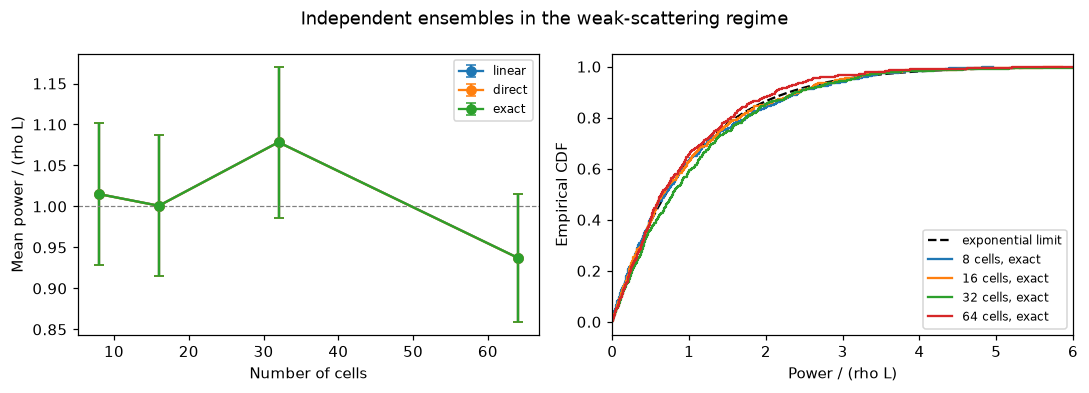

In [7]:
family_error = .01
cdf_bound = np.sqrt(np.log(2*len(cell_counts)/family_error)/(2*ensemble_size))
print(f'Single-scattering DKW bound: {cdf_bound:.5f} (family error probability {family_error:g})')
print('cells   E|r/sqrt(rho*h)|^2   mean P/(rho*L): linear / direct / exact    var(linear P)/(rho*L)^2  CDF gap')
for row in results:
    coeff = row['coefficients']
    coeff_power = np.mean(abs(coeff)**2)
    assert abs(coeff_power-1.) < 6/np.sqrt(coeff.size)
    assert abs(np.mean(coeff)) < 6/np.sqrt(coeff.size)
    powers = [abs(row[name][:, 0])**2/power_scale for name in ('linear', 'direct', 'exact')]
    means = [np.mean(value) for value in powers]
    variance = np.var(powers[0], ddof=1)
    assert abs(means[0]-1.) < 6/np.sqrt(ensemble_size)
    assert abs(variance-1.) < 6*np.sqrt(8/ensemble_size)
    z = np.sort(powers[0])
    theory = 1.-np.exp(-z)
    empirical = np.arange(1, ensemble_size+1)/ensemble_size
    cdf_gap = max(np.max(empirical-theory), np.max(theory-(empirical-1/ensemble_size)))
    assert cdf_gap < cdf_bound
    row.update(powers=powers, means=means, cdf_gap=cdf_gap)
    print(f'{row["cells"]:5}     {coeff_power:.6f}              {means[0]:.6f} / {means[1]:.6f} / {means[2]:.6f}'
          f'          {variance:.6f}                 {cdf_gap:.5f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for index, name in enumerate(('linear', 'direct', 'exact')):
    means = [np.mean(row['powers'][index]) for row in results]
    errors = [2*np.std(row['powers'][index], ddof=1)/np.sqrt(ensemble_size) for row in results]
    axes[0].errorbar(cell_counts, means, yerr=errors, marker='o', capsize=3, label=name)
axes[0].axhline(1., color='gray', ls='--', lw=.8)
axes[0].set(xlabel='Number of cells', ylabel='Mean power / (rho L)')
axes[0].legend(fontsize=8)
x = np.linspace(0., 6., 300)
axes[1].plot(x, 1.-np.exp(-x), 'k--', label='exponential limit')
for row in results:
    z = np.sort(row['powers'][2])
    axes[1].step(z, np.arange(1, ensemble_size+1)/ensemble_size, where='post', label=f'{row["cells"]} cells, exact')
axes[1].set(xlabel='Power / (rho L)', ylabel='Empirical CDF', xlim=(0., 6.))
axes[1].legend(fontsize=8)
fig.suptitle('Independent ensembles in the weak-scattering regime')
fig.tight_layout()
plt.show()

## Complex covariance: grid bias and Monte Carlo error

The deterministic difference between C_N and C_infinity measures a left-edge
quadrature bias in this single-scattering reference. The measured covariance
has separate sampling uncertainty. Below, complex RMS error is normalized by
rho L; the per-offset standard error is estimated across realizations.

The exact/direct-consistent difference keeps the same local transmissions.
The exact/legacy difference also includes the legacy model's missing depletion.
These differences must not be interpreted as interchangeable multipath metrics.

cells   discrete-continuum max gap   measured-discrete RMS   covariance SE max   exact-direct rel L2   exact-legacy rel L2
    8       0.188453                     0.034695               0.046470             7.326e-05             9.231e-05
   16       0.066481                     0.043989               0.046167             8.186e-05             1.008e-04
   32       0.031596                     0.037150               0.048379             8.203e-05             1.019e-04
   64       0.015667                     0.053117               0.044825             7.892e-05             9.724e-05


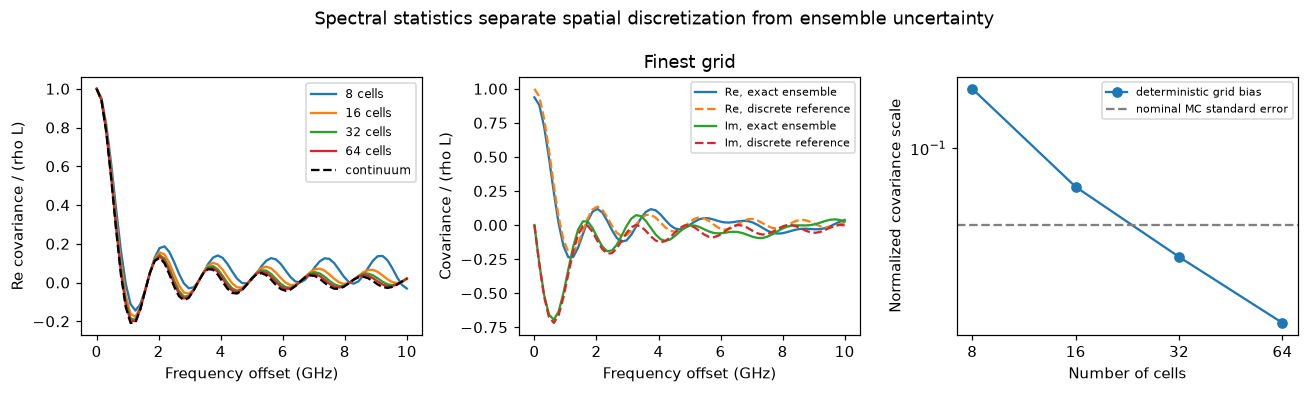

In [8]:
print('cells   discrete-continuum max gap   measured-discrete RMS   covariance SE max   exact-direct rel L2   exact-legacy rel L2')
for row in results:
    products = row['linear']*np.conj(row['linear'][:, :1])
    covariance = np.mean(products, axis=0)
    covariance_exact = np.mean(row['exact']*np.conj(row['exact'][:, :1]), axis=0)
    standard_error = np.std(products, axis=0, ddof=1)/np.sqrt(ensemble_size)
    bias = np.max(abs(row['covariance_discrete']-covariance_continuum))/power_scale
    error = np.linalg.norm(covariance-row['covariance_discrete'])/(np.sqrt(len(frequency))*power_scale)
    assert error < 6/np.sqrt(ensemble_size)
    direct_error = np.linalg.norm(row['exact']-row['direct'])/np.linalg.norm(row['exact'])
    legacy_error = np.linalg.norm(row['exact']-row['linear'])/np.linalg.norm(row['exact'])
    assert direct_error < .002 and legacy_error < .002
    row.update(covariance=covariance, covariance_exact=covariance_exact, covariance_se=standard_error, bias=bias)
    print(f'{row["cells"]:5}       {bias:.6f}                     {error:.6f}               '
          f'{max(standard_error)/power_scale:.6f}             {direct_error:.3e}             {legacy_error:.3e}')
assert np.all(np.diff([row['bias'] for row in results]) < 0.)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for row in results:
    axes[0].plot(offset/1e9, row['covariance_discrete'].real/power_scale, label=f'{row["cells"]} cells')
axes[0].plot(offset/1e9, covariance_continuum.real/power_scale, 'k--', label='continuum')
axes[0].set(xlabel='Frequency offset (GHz)', ylabel='Re covariance / (rho L)')
axes[0].legend(fontsize=8)
fine = results[-1]
for component, label in ((np.real, 'Re'), (np.imag, 'Im')):
    axes[1].plot(offset/1e9, component(fine['covariance_exact'])/power_scale, label=label+', exact ensemble')
    axes[1].plot(offset/1e9, component(fine['covariance_discrete'])/power_scale, '--', label=label+', discrete reference')
axes[1].set(xlabel='Frequency offset (GHz)', ylabel='Covariance / (rho L)', title='Finest grid')
axes[1].legend(fontsize=7)
axes[2].loglog(cell_counts, [row['bias'] for row in results], 'o-', label='deterministic grid bias')
axes[2].axhline(1/np.sqrt(ensemble_size), color='gray', ls='--', label='nominal MC standard error')
axes[2].set(xlabel='Number of cells', ylabel='Normalized covariance scale')
axes[2].set_xticks(cell_counts, labels=[str(count) for count in cell_counts])
axes[2].minorticks_off()
axes[2].legend(fontsize=7)
fig.suptitle('Spectral statistics separate spatial discretization from ensemble uncertainty')
fig.tight_layout()
plt.show()

This is one reproducible weak, uniform, lossless reference case. Good power
statistics do not prove phase convergence for a frozen realization. The
deterministic covariance bias decreases here, while measured ensemble errors
fluctuate and need not decrease monotonically with cell count.

The example does not establish convergence for strong backscatter, point
cavities, heterogeneous sections or perturbed states. Coupled spatial
refinement, phase/position rules and a statistical study in those regimes
remain separate work. No matching of individual complex fields is expected
between the independent grids used here.